# UABR-SLM · Notebook 00 — PopQA splits, aliases, relation prior, pilot set

**Phase 00 of 11** (see `docs/PLAN.md` §3, §7.1, §8, amendment A9). CPU only, ~2–5 min.

**What this notebook produces** (in `/kaggle/working/00_popqa_splits/`):

| file | contents |
|---|---|
| `popqa_prepared.jsonl` | all 14,267 PopQA rows + gold aliases, popularity bin, group id, split, pilot flag, relation-prior correctness |
| `manifests/*.txt` | question ids per split (`train/val/test/ood/pilot`) — **commit these to git** (`data/splits/`) |
| `relation_prior.csv` | best constant answer per relation and its accuracy per split (PLAN §7.1) |
| `split_summary.csv`, `popbin_edges.json` | counts by relation × split × popularity bin |
| `meta.json` | config, seed, data fingerprint, HF revision, code commit |
| `gate_report.json` | split-integrity checks (PASS / WARN / FAIL) |

**Kaggle settings:** Accelerator **None** · Internet **On** (downloads PopQA from Hugging Face and clones the code repo).
Then **Save Version → Save & Run All** so the output can be attached to notebook 01/04 via *Add Input → Your Work*.

**Design decisions (frozen here):**
- Splits are grouped by **subject and by identical question text** (homonyms like two different "John Smith"s share a group) and stratified by relation × popularity bin: 70 / 15 / 15.
- **OOD relations** (`religion`, `mother`, `capital of`) are held out of train/val/test entirely. OOD rows whose subject also appears in train are flagged (`group_in_train`).
- The **500 pilot questions come from validation only** and are never in test (A9).
- **Relation prior** = the constant answer that maximises alias-aware EM on *train* for that relation. A question counts as "known" later only if the model beats this.
- PopQA questions are template-generated from Wikidata, not human-written.

## 1 · Get the project code

In [1]:
import os, sys, glob, json, subprocess, platform
ON_KAGGLE = os.path.exists("/kaggle/working")

REPO_URL = "https://github.com/Prajwal-13-dev/uabr_slm.git"
REPO_REF = "main"        # pin to a commit hash for final, reportable runs

def find_code_root():
    # (a) local testing override
    if os.environ.get("UABR_CODE"):
        return os.path.abspath(os.environ["UABR_CODE"])
    # (b) repo uploaded as a Kaggle dataset (any name) attached under /kaggle/input
    for base in glob.glob("/kaggle/input/*"):
        for root, dirs, _ in os.walk(base):
            if os.path.isdir(os.path.join(root, "src", "uabr")):
                return root
            if root.count(os.sep) - base.count(os.sep) >= 4:
                dirs[:] = []
    # (c) git clone (public repo, or private with a Kaggle secret named GITHUB_TOKEN)
    dest = "/tmp/uabr_slm"
    if not os.path.isdir(dest):
        url = REPO_URL
        try:
            from kaggle_secrets import UserSecretsClient
            tok = UserSecretsClient().get_secret("GITHUB_TOKEN")
            url = url.replace("https://", f"https://{tok}@")
        except Exception:
            pass
        subprocess.run(["git", "clone", "-q", url, dest], check=True)
        subprocess.run(["git", "-C", dest, "checkout", "-q", REPO_REF], check=True)
    return dest

CODE_ROOT = find_code_root()
sys.path.insert(0, os.path.join(CODE_ROOT, "src"))
try:
    CODE_COMMIT = subprocess.run(["git", "-C", CODE_ROOT, "rev-parse", "HEAD"],
                                 capture_output=True, text=True).stdout.strip() or "unknown"
except Exception:
    CODE_COMMIT = "unknown"

from uabr.data import popqa as P
from uabr.eval.metrics import alias_em
print("code:", CODE_ROOT, "| commit:", CODE_COMMIT[:10])

code: /tmp/uabr_slm | commit: 24ce903659


## 2 · Configuration

In [2]:
import numpy as np, pandas as pd

OUT_DIR = "/kaggle/working/00_popqa_splits" if ON_KAGGLE else os.path.abspath("outputs/00_popqa_splits")
os.makedirs(os.path.join(OUT_DIR, "manifests"), exist_ok=True)

# Optional: path to a local copy of PopQA (csv/tsv/parquet/jsonl), e.g. if Internet is off.
POPQA_SOURCE = os.environ.get("POPQA_SOURCE") or None
HF_REVISION  = None      # None = latest; the resolved sha is recorded in meta.json

cfg = P.SplitConfig(
    seed=1234,
    train_frac=0.70, val_frac=0.15, test_frac=0.15, n_folds=20,
    n_pop_bins=5,
    ood_relations=("religion", "mother", "capital of"),
    pilot_size=500, pilot_min_per_relation=15,
)
pd.set_option("display.width", 160, "display.max_columns", 30)
cfg.to_dict()

{'seed': 1234,
 'train_frac': 0.7,
 'val_frac': 0.15,
 'test_frac': 0.15,
 'n_folds': 20,
 'n_pop_bins': 5,
 'ood_relations': ['religion', 'mother', 'capital of'],
 'pilot_size': 500,
 'pilot_min_per_relation': 15,
 'majority_candidates': 30}

## 3 · Load PopQA

In [3]:
try:
    raw = P.load_popqa(POPQA_SOURCE, revision=HF_REVISION)
except Exception as e:
    raise RuntimeError(
        "Could not load PopQA. On Kaggle: Settings → Internet → On, or attach a copy of "
        "PopQA and set POPQA_SOURCE to its path.\n" + repr(e))

HF_SHA = None if POPQA_SOURCE else P.hub_revision_sha()
FINGERPRINT = P.fingerprint(raw)
print(f"{len(raw):,} rows | columns: {list(raw.columns)}")
print("HF revision:", HF_SHA, "| content fingerprint:", FINGERPRINT)
raw.head(3)

README.md:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


test.tsv:   0%|          | 0.00/5.21M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/14267 [00:00<?, ? examples/s]

14,267 rows | columns: ['id', 'subj', 'prop', 'obj', 'subj_id', 'prop_id', 'obj_id', 's_aliases', 'o_aliases', 's_uri', 'o_uri', 's_wiki_title', 'o_wiki_title', 's_pop', 'o_pop', 'question', 'possible_answers']
HF revision: 098765c79ea10a2cb19c828324e33281b8336ec0 | content fingerprint: b2b46747a386725c


,id,subj,prop,obj,subj_id,prop_id,obj_id,s_aliases,o_aliases,s_uri,o_uri,s_wiki_title,o_wiki_title,s_pop,o_pop,question,possible_answers
0,4222362,George Rankin,occupation,politician,1850297,22,2834605,"[""George James Rankin""]","[""political leader"",""political figure"",""polit....",http://www.wikidata.org/entity/Q5543720,http://www.wikidata.org/entity/Q82955,George Rankin,Politician,142,25692,What is George Rankin's occupation?,"[""politician"", ""political leader"", ""political ..."
1,4725190,John Mayne,occupation,journalist,2079053,22,663400,[],"[""journo"",""journalists""]",http://www.wikidata.org/entity/Q6247345,http://www.wikidata.org/entity/Q1930187,John Mayne,Journalist,236,24952,What is John Mayne's occupation?,"[""journalist"", ""journo"", ""journalists""]"
2,4382392,Henry Feilden,occupation,politician,1925450,22,2834605,"[""Henry Master Feilden""]","[""political leader"",""political figure"",""polit....",http://www.wikidata.org/entity/Q5725578,http://www.wikidata.org/entity/Q82955,Henry Feilden (Conservative politician),Politician,58,25692,What is Henry Feilden's occupation?,"[""politician"", ""political leader"", ""political ..."


## 4 · Clean: gold aliases, popularity, homonyms

In [4]:
df = P.prepare(raw)
rel = df["prop"].value_counts().rename("n").to_frame()
rel["distinct_answers"] = df.groupby("prop")["answer"].nunique()
rel["top_answer_share"] = df.groupby("prop")["answer"].agg(lambda s: s.value_counts(normalize=True).iloc[0]).round(3)
rel["median_s_pop"] = df.groupby("prop")["s_pop"].median().astype(int)
print(f"relations: {df['prop'].nunique()} | subjects: {df['subj_id'].nunique():,}")
print(f"aliases per question: median {df['n_aliases'].median():.0f}, max {df['n_aliases'].max()}")
print(f"ambiguous (same question text, different subjects): {int(df['ambiguous_question'].sum())} rows")
rel.sort_values("n", ascending=False)

relations: 16 | subjects: 12,244
aliases per question: median 2, max 179
ambiguous (same question text, different subjects): 1689 rows


,n,distinct_answers,top_answer_share,median_s_pop
prop,,,,
director,1999,1521,0.004,996
screenwriter,1999,1468,0.008,1777
genre,1619,283,0.042,866
producer,1520,1133,0.009,2388
author,1514,1158,0.015,385
composer,978,624,0.017,1533
country,838,107,0.331,199
capital,645,584,0.011,25227
place of birth,584,434,0.022,175


## 5 · Groups and popularity bins

In [5]:
df = P.add_groups(df)
df, POP_EDGES = P.add_pop_bins(df, cfg.n_pop_bins)
sizes = df.groupby("group_id").size()
print(f"{df['group_id'].nunique():,} groups | rows per group: mean {sizes.mean():.2f}, max {sizes.max()}")
print("popularity bin edges (monthly page views):", [round(10**e) for e in POP_EDGES])
df["pop_bin"].value_counts().sort_index()

11,402 groups | rows per group: mean 1.25, max 64
popularity bin edges (monthly page views): [2, 179, 553, 1840, 9747, 15101521]


pop_bin
0    2847
1    2858
2    2855
3    2852
4    2855
Name: count, dtype: int64

## 6 · Split: 70 / 15 / 15 grouped + stratified, OOD relations held out

In [6]:
import warnings
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="The least populated class")
    df = P.assign_splits(df, cfg)

print(df["split"].value_counts().to_string())
ind = df[df["split"] != "ood"]
print("\nin-distribution fractions:", ind["split"].value_counts(normalize=True).round(4).to_dict())
ood = df[df["split"] == "ood"]
print(f"OOD rows: {len(ood)} | of which subject-group also in train: {int(ood['group_in_train'].sum())}")
pd.crosstab(df["prop"], df["split"], margins=True)

split
train    9327
test     2086
val      1966
ood       888

in-distribution fractions: {'train': 0.6971, 'test': 0.1559, 'val': 0.1469}
OOD rows: 888 | of which subject-group also in train: 96


split,ood,test,train,val,All
prop,,,,,
author,0,235,1064,215,1514
capital,0,98,453,94,645
capital of,363,0,0,0,363
color,0,6,24,4,34
composer,0,142,686,150,978
country,0,125,582,131,838
director,0,342,1368,289,1999
father,0,81,401,88,570
genre,0,244,1135,240,1619


## 7 · Pilot set: 500 validation questions (dev-only, never test)

In [7]:
df = P.select_pilot(df, cfg)
pilot = df[df["is_pilot"]]
print(f"pilot: {len(pilot)} questions, splits = {pilot['split'].value_counts().to_dict()}")
pd.concat([pilot["prop"].value_counts().rename("pilot_n"),
           pd.crosstab(pilot["prop"], pilot["pop_bin"])], axis=1)

pilot: 500 questions, splits = {'val': 500}


,pilot_n,0,1,2,3,4
prop,,,,,,
director,72,10,18,16,17,11
screenwriter,71,4,16,18,18,15
genre,60,10,14,16,10,10
producer,56,4,10,12,16,14
author,54,14,17,12,8,3
composer,38,4,5,9,11,9
country,33,17,8,2,5,1
capital,24,2,1,4,2,15
place of birth,23,12,6,3,1,1


## 8 · Relation-prior baseline (PLAN §7.1)
Best *constant* answer per relation, chosen on train with alias-aware EM. G1 asks whether closed-book EM beats this by ≥5–10 pp.

In [8]:
prior_tab, df["prior_correct"] = P.relation_majority(df, cfg)
overall = {s: round(float(df.loc[df["split"] == s, "prior_correct"].mean()), 4) for s in ["train", "val", "test", "ood"]}
overall["pilot"] = round(float(df.loc[df["is_pilot"], "prior_correct"].mean()), 4)
print("relation-prior EM overall:", overall)
prior_tab[["relation", "prior_answer", "prior_fit_on", "n_distinct_answers",
           "acc_train", "acc_val", "acc_test", "acc_ood", "acc_pilot"]].round(3)

relation-prior EM overall: {'train': 0.0716, 'val': 0.0783, 'test': 0.0729, 'ood': 0.1689, 'pilot': 0.074}


,relation,prior_answer,prior_fit_on,n_distinct_answers,acc_train,acc_val,acc_test,acc_ood,acc_pilot
0,author,Isaac Asimov,train,1158,0.015,0.014,0.013,NaN,0.019
1,capital,London,train,584,0.022,0.000,0.000,NaN,0.000
2,capital of,Kingdom of England,ood(oracle),356,NaN,NaN,NaN,0.030,NaN
3,color,red,train,5,0.750,1.000,0.667,NaN,1.000
4,composer,Richard Rodgers,train,624,0.019,0.027,0.000,NaN,0.000
5,country,United States of America,train,107,0.326,0.305,0.392,NaN,0.242
6,director,Joss Whedon,train,1521,0.005,0.000,0.000,NaN,0.000
7,father,Zeus,train,524,0.010,0.011,0.012,NaN,0.000
8,genre,horror film,train,283,0.051,0.033,0.061,NaN,0.033
9,mother,Themis,ood(oracle),173,NaN,NaN,NaN,0.011,NaN


## 9 · Plots

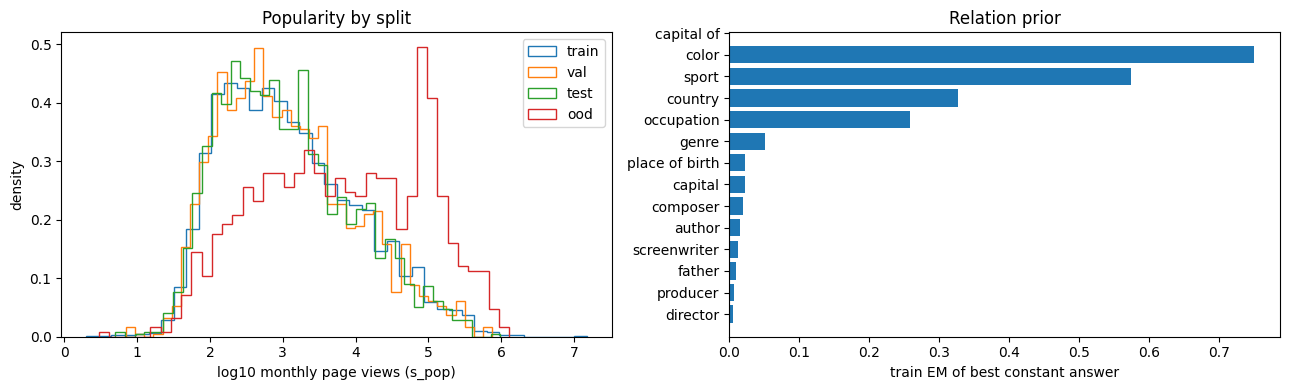

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for s in ["train", "val", "test", "ood"]:
    ax[0].hist(df.loc[df["split"] == s, "log_pop"], bins=40, histtype="step", density=True, label=s)
ax[0].set(xlabel="log10 monthly page views (s_pop)", ylabel="density", title="Popularity by split"); ax[0].legend()
p = prior_tab.set_index("relation")["acc_train"].sort_values()
ax[1].barh(p.index, p.values); ax[1].set(xlabel="train EM of best constant answer", title="Relation prior")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "splits_overview.png"), dpi=120); plt.show()

## 10 · Save outputs

In [10]:
KEEP = ["id", "subj", "subj_id", "prop", "prop_id", "obj", "obj_id", "answer", "gold_aliases",
        "s_aliases", "o_aliases", "s_wiki_title", "o_wiki_title", "s_pop", "o_pop", "log_pop", "pop_bin",
        "question", "ambiguous_question", "group_id", "fold", "split", "is_pilot", "group_in_train", "prior_correct"]
df[KEEP].to_json(os.path.join(OUT_DIR, "popqa_prepared.jsonl"), orient="records", lines=True, force_ascii=False)

for s in ["train", "val", "test", "ood"]:
    ids = df.loc[df["split"] == s, "id"].sort_values()
    ids.to_csv(os.path.join(OUT_DIR, "manifests", f"{s}_ids.txt"), index=False, header=False)
df.loc[df["is_pilot"], "id"].sort_values().to_csv(
    os.path.join(OUT_DIR, "manifests", "pilot_ids.txt"), index=False, header=False)

prior_tab.to_csv(os.path.join(OUT_DIR, "relation_prior.csv"), index=False)
(df.groupby(["prop", "split", "pop_bin"]).size().rename("n").reset_index()
   .to_csv(os.path.join(OUT_DIR, "split_summary.csv"), index=False))
json.dump({"log10_edges": POP_EDGES, "pageview_edges": [10**e for e in POP_EDGES]},
          open(os.path.join(OUT_DIR, "popbin_edges.json"), "w"), indent=2)

meta = {
    "notebook": "00_popqa_splits", "config": cfg.to_dict(),
    "popqa": {"source": POPQA_SOURCE or f"hf:{P.HF_DATASET}", "hf_revision": HF_SHA,
              "fingerprint": FINGERPRINT, "rows": len(df)},
    "code": {"repo": REPO_URL, "ref": REPO_REF, "commit": CODE_COMMIT},
    "env": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__},
    "counts": df["split"].value_counts().to_dict(), "pilot": int(df["is_pilot"].sum()),
    "relation_prior_overall": overall,
}
json.dump(meta, open(os.path.join(OUT_DIR, "meta.json"), "w"), indent=2, default=str)
for f in sorted(glob.glob(os.path.join(OUT_DIR, "**", "*"), recursive=True)):
    if os.path.isfile(f):
        print(f"{os.path.getsize(f)/1e6:8.2f} MB  {os.path.relpath(f, OUT_DIR)}")

    0.01 MB  manifests/ood_ids.txt
    0.00 MB  manifests/pilot_ids.txt
    0.02 MB  manifests/test_ids.txt
    0.07 MB  manifests/train_ids.txt
    0.02 MB  manifests/val_ids.txt
    0.00 MB  meta.json
    0.00 MB  popbin_edges.json
    8.70 MB  popqa_prepared.jsonl
    0.00 MB  relation_prior.csv
    0.00 MB  split_summary.csv
    0.06 MB  splits_overview.png


## 11 · Gate: split integrity

In [11]:
expected = 14267 if POPQA_SOURCE is None else len(raw)
checks = P.split_checks(df, cfg, expected_rows=expected)
fails = [c for c in checks if not c["passed"] and c["severity"] == "fail"]
warns = [c for c in checks if not c["passed"] and c["severity"] == "warn"]
status = "FAIL" if fails else ("PASS_WITH_WARNINGS" if warns else "PASS")
for c in checks:
    tag = "PASS" if c["passed"] else c["severity"].upper()
    print(f"[{tag:4}] {c['name']:<36} {c['detail']}")
json.dump({"gate": "00_splits", "status": status, "checks": checks},
          open(os.path.join(OUT_DIR, "gate_report.json"), "w"), indent=2)
print("\nGATE 00:", status)
assert not fails, "Split gate failed - do not continue to later notebooks."

[PASS] row_count                            14267 rows (expected 14267)
[PASS] no_group_leak                        0 groups span >1 split
[PASS] no_subject_leak                      0 subjects span >1 split
[PASS] ood_relations_isolated               ood relations: ['capital of', 'mother', 'religion']
[PASS] pilot_size                           500 pilot questions
[PASS] pilot_in_val_only                    splits: {'val': 500}
[PASS] pilot_not_in_test                    A9
[PASS] gold_aliases_nonempty                0 empty
[PASS] overall_fractions_within_2pp         deviation {'train': -0.0029, 'val': -0.0031, 'test': 0.0059}
[PASS] per_relation_fractions_within_5pp    worst deviation 0.021
[PASS] popularity_balance_within_3pp        max pop-bin share gap vs train 0.014

GATE 00: PASS


## Next
1. Download `manifests/` and commit them to the repo under `data/splits/` (ids only, small).
2. Notebook **01** (corpus + tokenizer) will use `popqa_prepared.jsonl` to check that PopQA subject articles are in the Wikipedia snapshot.
3. Notebook **04** (G1 pilot) reads `manifests/pilot_ids.txt` and `relation_prior.csv`.